# 08.P · Solution: ShopWave product image classifier

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/08-deep-learning/project/solution.ipynb)

One complete answer to the [brief](README.md). Your numbers will differ slightly: augmentation, early stopping and hardware all add small variations.

In [1]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow's C++ start-up messages
warnings.filterwarnings("ignore")                # hide library deprecation notices
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
keras.utils.set_random_seed(42)                  # same start every run (results still vary slightly by machine)
print("Keras", keras.__version__, "· backend", keras.backend.backend())

import pathlib

def flower_folder():
    """Download the 5-class flower photos once (229 MB) and return the folder."""
    path = keras.utils.get_file(
        "flower_photos", untar=True,
        origin="https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz")
    return next(p.parent for p in pathlib.Path(path).rglob("daisy") if p.is_dir())

def load_flowers(n_train=200, n_val=40, n_test=100, size=160, seed=0):
    """Pick n images per class for train/val/test; return uint8 arrays (small in memory)."""
    root = flower_folder()
    classes = sorted(p.name for p in root.iterdir() if p.is_dir())
    rng = np.random.default_rng(seed)
    parts = {"train": (0, n_train), "val": (n_train, n_train + n_val),
             "test": (n_train + n_val, n_train + n_val + n_test)}
    data = {k: ([], []) for k in parts}
    for label, name in enumerate(classes):
        files = sorted((root / name).glob("*.jpg"))
        rng.shuffle(files)
        for k, (a, b) in parts.items():
            for f in files[a:b]:
                img = keras.utils.load_img(f, target_size=(size, size))
                data[k][0].append(np.asarray(img, dtype="uint8"))
                data[k][1].append(label)
    out = {k: (np.stack(v[0]), np.array(v[1])) for k, v in data.items()}
    return out, classes

from pathlib import Path

def models_dir():
    """The repo-root models/ folder (git-ignored); created if missing."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / "data").is_dir() and (parent / "modules").is_dir():
            folder = parent / "models"
            break
    else:
        folder = Path("models")
    folder.mkdir(exist_ok=True)
    return folder

def load_all_flowers(size=160, val_share=0.15, test_share=0.15, seed=0):
    """Every photo, split per class into train / validation / test. uint8 keeps memory small."""
    root = flower_folder()
    classes = sorted(p.name for p in root.iterdir() if p.is_dir())
    rng = np.random.default_rng(seed)
    split = {"train": ([], []), "val": ([], []), "test": ([], [])}
    for label, name in enumerate(classes):
        files = sorted((root / name).glob("*.jpg"))
        rng.shuffle(files)
        n_val, n_test = round(len(files) * val_share), round(len(files) * test_share)
        parts = {"val": files[:n_val], "test": files[n_val:n_val + n_test], "train": files[n_val + n_test:]}
        for k, fs in parts.items():
            for f in fs:
                split[k][0].append(np.asarray(keras.utils.load_img(f, target_size=(size, size)), dtype="uint8"))
                split[k][1].append(label)
    return {k: (np.stack(v[0]), np.array(v[1])) for k, v in split.items()}, classes

data, CLASSES = load_all_flowers()
(x_train, y_train), (x_val, y_val), (x_test, y_test) = data["train"], data["val"], data["test"]
print("classes:", CLASSES)
print("train", len(y_train), " val", len(y_val), " test", len(y_test))

Keras 3.15.1 · backend tensorflow


classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
train 2568  val 551  test 551


## 1. Look at the data

In [2]:
import pandas as pd
counts = pd.DataFrame({k: np.bincount(v[1]) for k, v in data.items()}, index=CLASSES)
counts["total"] = counts.sum(axis=1)
print(counts)
baseline = np.bincount(y_test).max() / len(y_test)
print(f"\nalways predict '{CLASSES[np.bincount(y_train).argmax()]}': test accuracy {baseline:.3f}")

            train  val  test  total
daisy         443   95    95    633
dandelion     628  135   135    898
roses         449   96    96    641
sunflowers    489  105   105    699
tulips        559  120   120    799

always predict 'dandelion': test accuracy 0.245


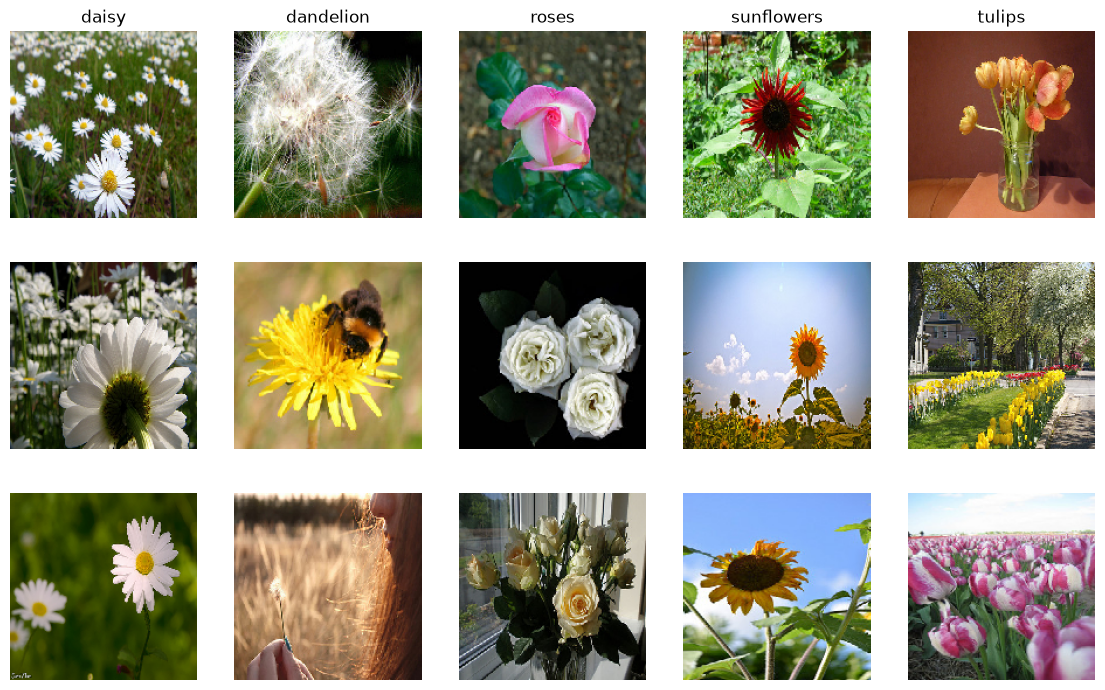

In [3]:
fig, axes = plt.subplots(3, 5, figsize=(14, 8.5))
for label in range(5):
    for row, i in enumerate(np.where(y_train == label)[0][:3]):
        axes[row, label].imshow(x_train[i]); axes[row, label].axis("off")
    axes[0, label].set_title(CLASSES[label])
plt.show()

The classes are fairly balanced (dandelion is largest), so accuracy is a reasonable headline metric, backed up by per-class recall. The photos vary a lot: close-ups, fields, bouquets, people in some shots.

## 2. Build the model

EfficientNetB0 was the more accurate base in 08.9. ShopWave runs tagging on a server, so its extra size is fine.

In [4]:
def build_tagger(n_classes):
    augment = keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.1),
                                layers.RandomZoom(0.1)], name="augment")
    base = keras.applications.EfficientNetB0(input_shape=(160, 160, 3), include_top=False,
                                             weights="imagenet", pooling="avg")
    base.trainable = False
    inputs = keras.Input((160, 160, 3))
    x = base(augment(inputs), training=False)
    outputs = layers.Dense(n_classes, activation="softmax")(layers.Dropout(0.2)(x))
    return keras.Model(inputs, outputs, name="shopwave_flower_tagger")

keras.utils.set_random_seed(42)
model = build_tagger(len(CLASSES))
trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"trainable weights {trainable:,}   frozen weights {model.count_params() - trainable:,}")

trainable weights 6,405   frozen weights 4,049,571


## 3. Train with early stopping

In [5]:
import time
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
start = time.time()
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=15,
                    batch_size=32, callbacks=[stop], verbose=0)
best = int(np.argmin(history.history["val_loss"])) + 1
print(f"ran {len(history.history['loss'])} epochs, best at epoch {best}, {time.time() - start:.0f} s")

ran 15 epochs, best at epoch 15, 122 s


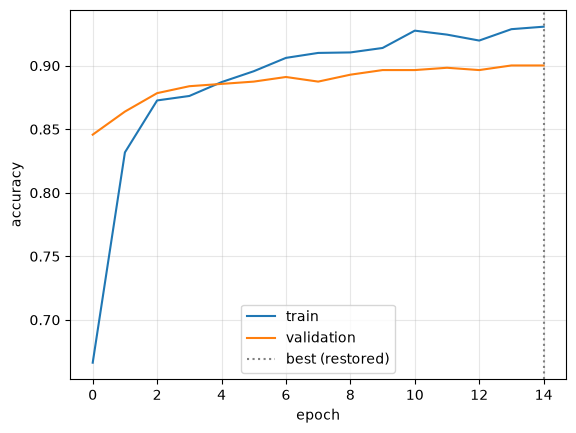

In [6]:
plt.plot(history.history["accuracy"], label="train"); plt.plot(history.history["val_accuracy"], label="validation")
plt.axvline(best - 1, color="gray", linestyle=":", label="best (restored)")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show()

Validation accuracy climbs quickly and then levels off around 0.90, while training accuracy keeps rising past it: the new head is starting to fit the training photos. Validation *loss* was still edging down at epoch 15, so early stopping never fired and the best weights are the last ones. Allowing more epochs is a stretch task; expect small gains at most.

## 4. Evaluate on the test set

In [7]:
from sklearn.metrics import classification_report, confusion_matrix
probs = model.predict(x_test, verbose=0)
pred, conf = probs.argmax(1), probs.max(1)
print(f"test accuracy {np.mean(pred == y_test):.3f}   (baseline {baseline:.3f})\n")
print(classification_report(y_test, pred, target_names=CLASSES, digits=3))
print(pd.DataFrame(confusion_matrix(y_test, pred), index=CLASSES, columns=CLASSES))

test accuracy 0.868   (baseline 0.245)

              precision    recall  f1-score   support

       daisy      0.876     0.895     0.885        95
   dandelion      0.901     0.948     0.924       135
       roses      0.843     0.781     0.811        96
  sunflowers      0.868     0.876     0.872       105
      tulips      0.838     0.817     0.827       120

    accuracy                          0.868       551
   macro avg      0.865     0.863     0.864       551
weighted avg      0.867     0.868     0.867       551

            daisy  dandelion  roses  sunflowers  tulips
daisy          85          4      2           2       2
dandelion       5        128      0           2       0
roses           3          1     75           5      12
sunflowers      1          6      1          92       5
tulips          3          3     11           5      98


## 5. Error analysis

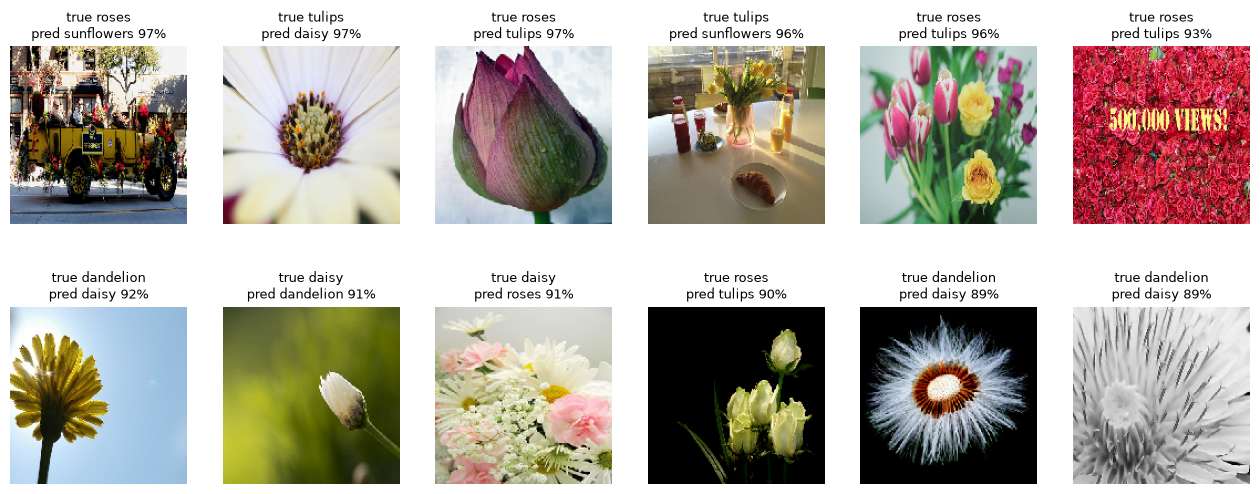

73 mistakes out of 551; 20 of them made with over 80% confidence


In [8]:
wrong = np.where(pred != y_test)[0]
show = wrong[np.argsort(-conf[wrong])][:12]               # most confident mistakes first
fig, axes = plt.subplots(2, 6, figsize=(16, 6.2))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(x_test[i]); ax.axis("off")
    ax.set_title(f"true {CLASSES[y_test[i]]}\npred {CLASSES[pred[i]]} {conf[i]:.0%}", fontsize=9)
plt.show()
print(f"{len(wrong)} mistakes out of {len(y_test)}; "
      f"{(conf[wrong] > 0.8).sum()} of them made with over 80% confidence")

Looking through the most confident mistakes, they fall into a few groups:

- **The flower is not the subject**: a parade float decorated with roses, a breakfast table with a vase. The photo has no single obvious answer.
- **Mixed bouquets**: tulips and roses together, daisies with roses and carnations. Roses and tulips are also the pair the confusion matrix mixes up most (12 and 11 photos).
- **Unusual views**: a dandelion seen from below against the sky, a single closed bud, a grey-scale close-up, a dandelion seed head (which looks nothing like a yellow dandelion).
- **Text and graphics**: a wall of roses with "500,000 VIEWS!" written across it.
- **Doubtful labels**: a few photos look mislabelled in the source data (a "tulip" that looks like a daisy-like flower). A model cannot be more right than its labels.

## 6. A confidence rule for the tagging team

In [9]:
rows = []
for t in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    auto = conf >= t
    rows.append({"threshold": t, "auto-tagged share": auto.mean(),
                 "accuracy when auto-tagged": np.mean(pred[auto] == y_test[auto]),
                 "photos to a person (of 100)": round(100 * (1 - auto.mean()))})
pd.DataFrame(rows).round(3)

,threshold,auto-tagged share,accuracy when auto-tagged,photos to a person (of 100)
0,0.50,0.975,0.883,3
1,0.60,0.922,0.907,8
2,0.70,0.869,0.923,13
3,0.80,0.804,0.955,20
4,0.90,0.717,0.975,28
5,0.95,0.621,0.985,38


At a threshold of **0.8** the model tags most photos on its own with clearly higher accuracy than overall, and sends the rest to a person. Raising the threshold buys more accuracy but sends many more photos to the team. The right point depends on what a wrong tag costs (a rose shown under "tulips") against the cost of a person's minute; 0.8 is a sensible start to agree with the team.

## 7. Save, reload, and check

In [10]:
path = models_dir() / "shopwave_flower_tagger.keras"
model.save(path)
reloaded = keras.models.load_model(path)
same = np.allclose(reloaded.predict(x_test[:64], verbose=0), probs[:64], atol=1e-5)
print(f"saved {path.name} ({path.stat().st_size / 1e6:.1f} MB); reloaded predictions identical: {same}")

saved shopwave_flower_tagger.keras (17.1 MB); reloaded predictions identical: True


## 8. Ready to deploy?

*For the head of e-commerce.* The tagger is accurate on photos like those in the test set (86.8% correct overall, against 24.5% for always guessing the most common type), and it knows when it is unsure. With a confidence threshold of 0.8 it tagged 80% of the test photos on its own, 95.5% of them correctly, and passed the other 20 in every 100 to the team. Its weak spot is roses against tulips, and photos showing several flowers or unusual views.

Before going live we should: (1) test it on a week of *real* supplier uploads, which may look different from these photos (white studio backgrounds, packaging, text overlays); (2) add an "other / not a flower" option, because today it must pick one of five even for a photo of a vase; (3) log every low-confidence photo and the team's correction, and retrain monthly on them; (4) track the share of photos below the threshold as an early warning that uploads have changed (Module 10).